In [44]:
for _, row in arcadia_check.iterrows():
    print("Observation:", row["Observation_ID"])
    print("Research note:", row["Researcher_Note"])
    print("Method:", row["Method_or_Definition"])
    print("Source IDs:", row["Source_IDs"])

Observation: OBS_006
Research note: Separated Oct 2025 construction completion from Apr 2026 export start
Method: Reported investment in Arcadia lithium sulphate plant completed Oct 2025
Source IDs: SRC_08; SRC_32


In [43]:
arcadia_check = core_data[
    core_data["Indicator"] ==
    "Capex_Spent_Sulphate_Plant"
]

display(
    arcadia_check[
        [
            "Observation_ID",
            "Year",
            "Value",
            "Actual_or_Forecast",
            "Verification_Status",
            "Source_IDs",
            "Researcher_Note"
        ]
    ]
)

,Observation_ID,Year,Value,Actual_or_Forecast,Verification_Status,Source_IDs,Researcher_Note
5,OBS_006,2025,400000000.0,Actual,Corroborated,SRC_08; SRC_32,Separated Oct 2025 construction completion fro...


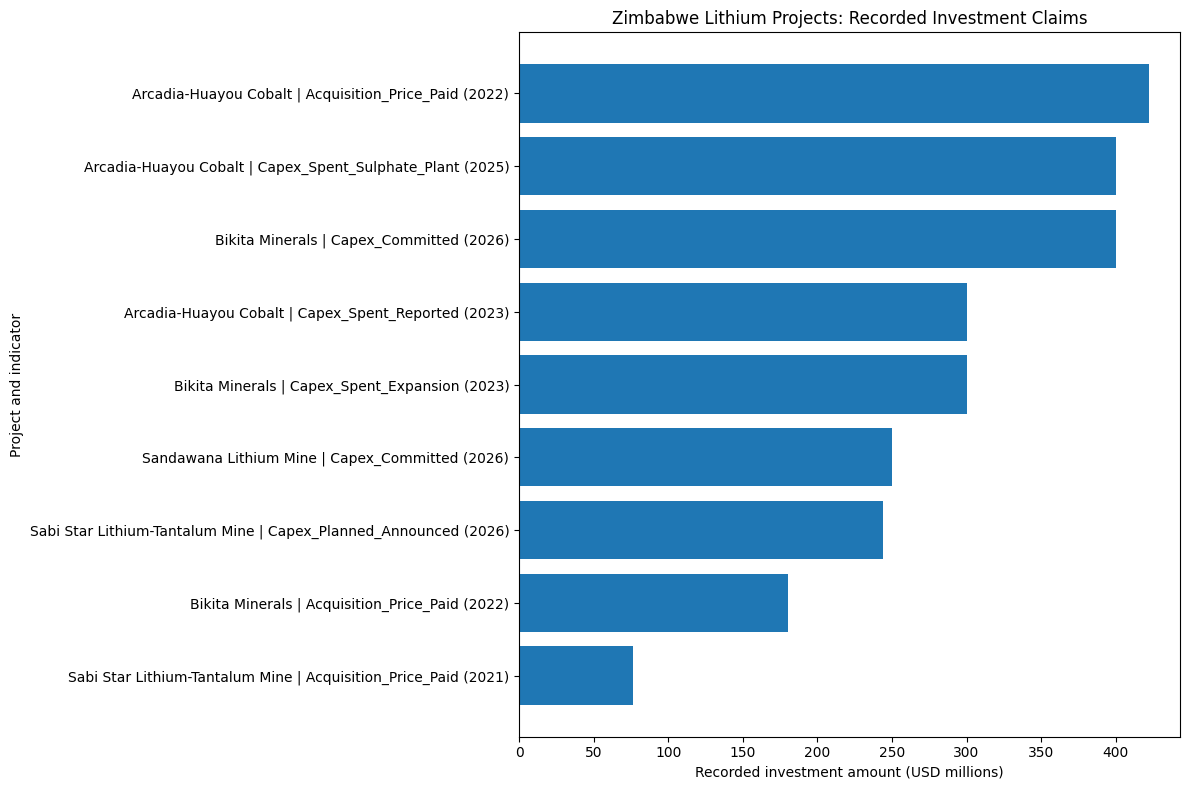

Investment chart created successfully!
Observations plotted: 9


In [42]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a copy without modifying the database
investment_chart = investment.copy()

# Convert USD to millions
investment_chart["USD_Million"] = (
    pd.to_numeric(investment_chart["Value"]) / 1_000_000
)

# Create labels
investment_chart["Label"] = (
    investment_chart["Project_Name"]
    + " | "
    + investment_chart["Indicator"]
    + " ("
    + investment_chart["Year"].astype(str)
    + ")"
)

# Sort by value
investment_chart = investment_chart.sort_values(
    "USD_Million"
)

plt.figure(figsize=(12, 8))

plt.barh(
    investment_chart["Label"],
    investment_chart["USD_Million"]
)

plt.xlabel("Recorded investment amount (USD millions)")
plt.ylabel("Project and indicator")
plt.title(
    "Zimbabwe Lithium Projects: Recorded Investment Claims"
)

plt.tight_layout()

plt.savefig(
    "Zimbabwe_Lithium_Investment_Claims_Preliminary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Investment chart created successfully!")
print("Observations plotted:", len(investment_chart))

In [41]:
# Select investment-related observations
investment = core_data[
    core_data["Indicator"].str.contains(
        "Acquisition|Capex|Investment",
        case=False,
        na=False
    )
].copy()

# Add project names
investment["Project_Name"] = investment[
    "Project_ID"
].map(project_names)

# Display investment records
display(
    investment[
        [
            "Project_Name",
            "Year",
            "Indicator",
            "Value",
            "Unit",
            "Actual_or_Forecast",
            "Verification_Status",
            "Source_IDs"
        ]
    ].sort_values(["Project_Name", "Year"])
)

print("Total investment observations:", len(investment))
print("\nInvestment indicators:")
print(investment["Indicator"].unique())

,Project_Name,Year,Indicator,Value,Unit,Actual_or_Forecast,Verification_Status,Source_IDs
1,Arcadia-Huayou Cobalt,2022,Acquisition_Price_Paid,422000000.0,USD,Actual,Corroborated,SRC_01; SRC_09
2,Arcadia-Huayou Cobalt,2023,Capex_Spent_Reported,300000000.0,USD,Actual,Corroborated,SRC_09
5,Arcadia-Huayou Cobalt,2025,Capex_Spent_Sulphate_Plant,400000000.0,USD,Actual,Corroborated,SRC_08; SRC_32
9,Bikita Minerals,2022,Acquisition_Price_Paid,180000000.0,USD,Actual,Corroborated,SRC_01; SRC_16
11,Bikita Minerals,2023,Capex_Spent_Expansion,300000000.0,USD,Actual,Corroborated,SRC_01
18,Bikita Minerals,2026,Capex_Committed,400000000.0,USD,Planned,Disputed,SRC_24
19,Sabi Star Lithium-Tantalum Mine,2021,Acquisition_Price_Paid,76500000.0,USD,Actual,Corroborated,SRC_01; SRC_02
23,Sabi Star Lithium-Tantalum Mine,2026,Capex_Planned_Announced,244000000.0,USD,Announced,Single-source claim,SRC_11
30,Sandawana Lithium Mine,2026,Capex_Committed,250000000.0,USD,Planned,Single-source claim,SRC_12


Total investment observations: 9

Investment indicators:
['Acquisition_Price_Paid' 'Capex_Spent_Reported'
 'Capex_Spent_Sulphate_Plant' 'Capex_Spent_Expansion' 'Capex_Committed'
 'Capex_Planned_Announced']


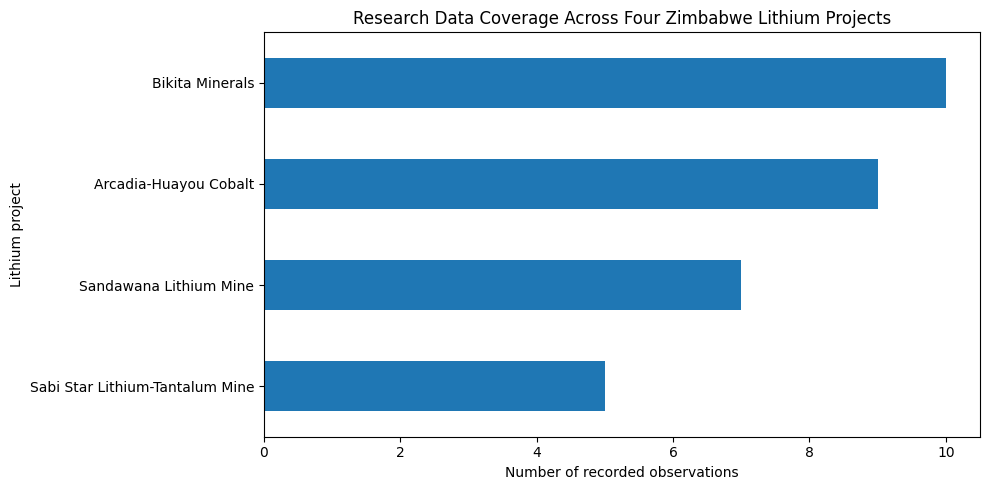

Chart saved successfully!


In [40]:
import matplotlib.pyplot as plt

# Count observations for each project
observation_counts = (
    core_data["Project_ID"]
    .value_counts()
    .rename(index=project_names)
    .sort_values()
)

# Create chart
plt.figure(figsize=(10, 5))

observation_counts.plot(kind="barh")

plt.xlabel("Number of recorded observations")
plt.ylabel("Lithium project")
plt.title(
    "Research Data Coverage Across Four Zimbabwe Lithium Projects"
)

plt.tight_layout()

# Save chart
plt.savefig(
    "Zimbabwe_Lithium_Data_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [39]:
# Create a research-ready comparative table

comparison = core_data[
    [
        "Project_ID",
        "Year",
        "Indicator",
        "Value",
        "Unit",
        "Source_IDs",
        "Verification_Status",
        "Actual_or_Forecast"
    ]
].copy()

# Add project names
project_names = projects.set_index(
    "Project_ID"
)["Project_Name"]

comparison["Project_Name"] = comparison[
    "Project_ID"
].map(project_names)

# Arrange columns
comparison = comparison[
    [
        "Project_Name",
        "Year",
        "Indicator",
        "Value",
        "Unit",
        "Actual_or_Forecast",
        "Verification_Status",
        "Source_IDs"
    ]
]

# Sort observations
comparison = comparison.sort_values(
    ["Project_Name", "Year", "Indicator"]
)

print("--- ZIMBABWE LITHIUM COMPARATIVE TABLE ---")
print("Total observations:", len(comparison))

display(comparison.head(15))

comparison.to_csv(
    "Zimbabwe_Lithium_Comparative_Research_Table.csv",
    index=False
)

print("Comparative research table exported!")

--- ZIMBABWE LITHIUM COMPARATIVE TABLE ---
Total observations: 31


,Project_Name,Year,Indicator,Value,Unit,Actual_or_Forecast,Verification_Status,Source_IDs
0,Arcadia-Huayou Cobalt,2021,Ore_Reserve_JORC,42.300,million tonnes,Actual,Primary verified,SRC_17
1,Arcadia-Huayou Cobalt,2022,Acquisition_Price_Paid,422000000.0,USD,Actual,Corroborated,SRC_01; SRC_09
2,Arcadia-Huayou Cobalt,2023,Capex_Spent_Reported,300000000.0,USD,Actual,Corroborated,SRC_09
3,Arcadia-Huayou Cobalt,2024,Concentrate_Exports,400000.0,tonnes,Actual,Single-source claim,SRC_09
5,Arcadia-Huayou Cobalt,2025,Capex_Spent_Sulphate_Plant,400000000.0,USD,Actual,Corroborated,SRC_08; SRC_32
4,Arcadia-Huayou Cobalt,2025,Employment_Direct_Local,2000.0,employees,Actual,Single-source claim,SRC_01
7,Arcadia-Huayou Cobalt,2025,Lithium_Sulphate_Capacity_Alt,60000.0,tonnes/year,Planned,Single-source claim,SRC_09
6,Arcadia-Huayou Cobalt,2025,Lithium_Sulphate_Capacity_SMM,50000.0,tonnes/year,Actual,Corroborated,SRC_08; SRC_32
8,Arcadia-Huayou Cobalt,2026,Lithium_Sulphate_Exports_Apr_Sep,33000.0,tonnes,Actual,Single-source claim,SRC_32
9,Bikita Minerals,2022,Acquisition_Price_Paid,180000000.0,USD,Actual,Corroborated,SRC_01; SRC_16


Comparative research table exported!


In [37]:
# Export source-linked evidence table

source_linked.to_csv(
    "Zimbabwe_Lithium_Source_Linked_Evidence.csv",
    index=False
)

print("Source-linked evidence table exported!")
print("Total evidence links:", len(source_linked))

Source-linked evidence table exported!
Total evidence links: 38


In [36]:
# Create one row for each observation-source pair
linked = report.copy()

linked["Source_ID"] = linked["Source_IDs"].str.split(";")
linked = linked.explode("Source_ID")

linked["Source_ID"] = linked["Source_ID"].str.strip()

# Attach source details
source_linked = linked.merge(
    sources[
        [
            "Source_ID",
            "Full_Citation",
            "Source_Type",
            "Reliability_Assessment",
            "Potential_Bias_or_Limitation"
        ]
    ],
    on="Source_ID",
    how="left",
    validate="many_to_one"
)

print("Observation-source links:", len(source_linked))

print(
    "Missing full citations:",
    source_linked["Full_Citation"].isna().sum()
)

display(source_linked.head())

Observation-source links: 38
Missing full citations: 0


,Observation_ID,Project_ID,Year,Indicator,Value,Unit,Source_IDs,Verification_Status,Actual_or_Forecast,Source_ID,Full_Citation,Source_Type,Reliability_Assessment,Potential_Bias_or_Limitation
0,OBS_001,Zim_L1,2021,Ore_Reserve_JORC,42.300,million tonnes,SRC_17,Primary verified,Actual,SRC_17,"Prospect Resources / Lycopodium. (2021, Decemb...",Corporate Technical Filing,High - ASX-regulated technical disclosure,Pre-Huayou ownership baseline
1,OBS_002,Zim_L1,2022,Acquisition_Price_Paid,422000000.0,USD,SRC_01; SRC_09,Corroborated,Actual,SRC_01,"Musasike, T., Radomski, J., Chidhawu, T., Mteg...",Academic / Policy Report,High - peer-reviewed policy center report with...,Government ministries & Chinese firms declined...
2,OBS_002,Zim_L1,2022,Acquisition_Price_Paid,422000000.0,USD,SRC_01; SRC_09,Corroborated,Actual,SRC_09,"Mining.com / Reuters. (2025, October 17). Huay...",Industry News / Wire Report,Medium-High - Reuters reporting of on-record e...,Company-reported capacity/production figures; ...
3,OBS_003,Zim_L1,2023,Capex_Spent_Reported,300000000.0,USD,SRC_09,Corroborated,Actual,SRC_09,"Mining.com / Reuters. (2025, October 17). Huay...",Industry News / Wire Report,Medium-High - Reuters reporting of on-record e...,Company-reported capacity/production figures; ...
4,OBS_004,Zim_L1,2024,Concentrate_Exports,400000.0,tonnes,SRC_09,Single-source claim,Actual,SRC_09,"Mining.com / Reuters. (2025, October 17). Huay...",Industry News / Wire Report,Medium-High - Reuters reporting of on-record e...,Company-reported capacity/production figures; ...


In [ ]:
# Prepare evidence traceability report
report = core_data[
    [
        "Observation_ID",
        "Project_ID",
        "Year",
        "Indicator",
        "Value",
        "Unit",
        "Source_IDs",
        "Verification_Status",
        "Actual_or_Forecast"
    ]
].copy()

# Export report
report.to_csv(
    "Zimbabwe_Lithium_Evidence_Traceability.csv",
    index=False
)

print("Evidence traceability report created!")
print("Total rows:", len(report))

display(report.head())

Evidence traceability report created!
Total rows: 31


,Observation_ID,Project_ID,Year,Indicator,Value,Unit,Source_IDs,Verification_Status,Actual_or_Forecast
0,OBS_001,Zim_L1,2021,Ore_Reserve_JORC,42.300,million tonnes,SRC_17,Primary verified,Actual
1,OBS_002,Zim_L1,2022,Acquisition_Price_Paid,422000000.0,USD,SRC_01; SRC_09,Corroborated,Actual
2,OBS_003,Zim_L1,2023,Capex_Spent_Reported,300000000.0,USD,SRC_09,Corroborated,Actual
3,OBS_004,Zim_L1,2024,Concentrate_Exports,400000.0,tonnes,SRC_09,Single-source claim,Actual
4,OBS_005,Zim_L1,2025,Employment_Direct_Local,2000.0,employees,SRC_01,Single-source claim,Actual


In [ ]:
# Load the source register
sources = pd.read_excel(
    file_path,
    sheet_name="Source_Register"
)

print("Source register columns:")
print(sources.columns.tolist())

# Extract individual source IDs
used_sources = set()

for entry in core_data["Source_IDs"].dropna():
    for source_id in str(entry).split(";"):
        source_id = source_id.strip()
        if source_id:
            used_sources.add(source_id)

# Compare with registered source IDs
registered_sources = set(
    sources["Source_ID"].dropna().astype(str).str.strip()
)

missing_sources = used_sources - registered_sources

print("\nUnique source IDs used:", len(used_sources))
print("Source IDs found in register:",
      len(used_sources & registered_sources))
print("Unmatched source IDs:", len(missing_sources))
print("Unmatched IDs:", sorted(missing_sources))

Source register columns:
['Source_ID', 'Full_Citation', 'Source_Type', 'Issuing_Actor', 'Publication_Date', 'Period_Covered', 'URL_or_Repository', 'Access_Date', 'Page_Range_or_Locator', 'Geographic_Coverage', 'Evidence_Type', 'Reliability_Assessment', 'Potential_Bias_or_Limitation', 'Used_In_Tables', 'Researcher_Notes']

Unique source IDs used: 12
Source IDs found in register: 12
Unmatched source IDs: 0
Unmatched IDs: []


In [ ]:
# Check evidence documentation
evidence_check = core_data[
    [
        "Observation_ID",
        "Project_ID",
        "Indicator",
        "Source_IDs",
        "Verification_Status",
        "Actual_or_Forecast"
    ]
].copy()

print("--- EVIDENCE TRACEABILITY REPORT ---")

print("Total observations:", len(evidence_check))

print(
    "Missing source references:",
    evidence_check["Source_IDs"]
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna().sum()
)

print("\nVerification status:")
print(
    evidence_check["Verification_Status"]
    .value_counts(dropna=False)
)

print("\nActual vs Forecast:")
print(
    evidence_check["Actual_or_Forecast"]
    .value_counts(dropna=False)
)

display(evidence_check.head(10))

--- EVIDENCE TRACEABILITY REPORT ---
Total observations: 31
Missing source references: 0

Verification status:
Verification_Status
Single-source claim    15
Corroborated           12
Disputed                3
Primary verified        1
Name: count, dtype: int64

Actual vs Forecast:
Actual_or_Forecast
Actual       25
Planned       3
Forecast      2
Announced     1
Name: count, dtype: int64


,Observation_ID,Project_ID,Indicator,Source_IDs,Verification_Status,Actual_or_Forecast
0,OBS_001,Zim_L1,Ore_Reserve_JORC,SRC_17,Primary verified,Actual
1,OBS_002,Zim_L1,Acquisition_Price_Paid,SRC_01; SRC_09,Corroborated,Actual
2,OBS_003,Zim_L1,Capex_Spent_Reported,SRC_09,Corroborated,Actual
3,OBS_004,Zim_L1,Concentrate_Exports,SRC_09,Single-source claim,Actual
4,OBS_005,Zim_L1,Employment_Direct_Local,SRC_01,Single-source claim,Actual
5,OBS_006,Zim_L1,Capex_Spent_Sulphate_Plant,SRC_08; SRC_32,Corroborated,Actual
6,OBS_007,Zim_L1,Lithium_Sulphate_Capacity_SMM,SRC_08; SRC_32,Corroborated,Actual
7,OBS_007B,Zim_L1,Lithium_Sulphate_Capacity_Alt,SRC_09,Single-source claim,Planned
8,OBS_007C,Zim_L1,Lithium_Sulphate_Exports_Apr_Sep,SRC_32,Single-source claim,Actual
9,OBS_008,Zim_L2,Acquisition_Price_Paid,SRC_01; SRC_16,Corroborated,Actual


In [ ]:
# Display all column names
print("--- OBSERVATION COLUMNS ---")

print(core_data.columns.tolist())

# Check whether Source_ID exists
if "Source_ID" in core_data.columns:
    print("\nSource_ID column found.")
    print(
        "Missing source IDs:",
        core_data["Source_ID"].isna().sum()
    )
else:
    print("\nSource_ID column not found.")
    print("We need to identify how sources are linked.")

--- OBSERVATION COLUMNS ---
['Observation_ID', 'Project_ID', 'Year', 'Indicator', 'Value', 'Unit', 'Standardised_Value', 'Standardised_Unit', 'Product_Form', 'Geographic_Level', 'Data_Status', 'Method_or_Definition', 'Source_IDs', 'Page_or_Table', 'Researcher_Note', 'Evidence_Type', 'Actual_or_Forecast', 'Verification_Status']

Source_ID column not found.
We need to identify how sources are linked.


In [ ]:
# Check missing values in important columns
important_columns = [
    "Project_ID",
    "Year",
    "Indicator",
    "Value",
    "Unit",
    "Source_ID"
]

# Check only columns that exist
available_columns = [
    col for col in important_columns
    if col in core_data.columns
]

missing_values = core_data[
    available_columns
].isna().sum()

print("--- MISSING VALUES REPORT ---")
print(missing_values)

print("\nTotal core observations:", len(core_data))

--- MISSING VALUES REPORT ---
Project_ID    0
Year          0
Indicator     0
Value         0
Unit          0
dtype: int64

Total core observations: 31


In [ ]:
# Select the four core case studies
core_projects = projects[
    projects["Core_Case_Study"]
    .astype(str).str.strip().str.lower() == "yes"
]

# Display core projects
display(
    core_projects[
        ["Project_ID", "Project_Name"]
    ]
)

print("Total core projects:", len(core_projects))

# Extract their observations
core_data = observations[
    observations["Project_ID"].isin(
        core_projects["Project_ID"]
    )
].copy()

print("Core project observations:", len(core_data))

# Check duplicate observation IDs
print(
    "Duplicate observation IDs:",
    core_data["Observation_ID"].duplicated().sum()
    if "Observation_ID" in core_data.columns
    else "Column not found"
)

,Project_ID,Project_Name
0,Zim_L1,Arcadia-Huayou Cobalt
1,Zim_L2,Bikita Minerals
2,Zim_L3,Sabi Star Lithium-Tantalum Mine
3,Zim_L4,Sandawana Lithium Mine


Total core projects: 4
Core project observations: 31
Duplicate observation IDs: 0


In [ ]:
import pandas as pd

# Load research database
projects = pd.read_excel(
    file_path,
    sheet_name="Project_Registry"
)

observations = pd.read_excel(
    file_path,
    sheet_name="Project_Annual_Observations"
)

print("Database loaded successfully!")
print("Total projects:", len(projects))
print("Total observations:", len(observations))

# Display project information
display(
    projects[
        ["Project_ID", "Project_Name", "Core_Case_Study"]
    ]
)

Database loaded successfully!
Total projects: 6
Total observations: 39


,Project_ID,Project_Name,Core_Case_Study
0,Zim_L1,Arcadia-Huayou Cobalt,Yes
1,Zim_L2,Bikita Minerals,Yes
2,Zim_L3,Sabi Star Lithium-Tantalum Mine,Yes
3,Zim_L4,Sandawana Lithium Mine,Yes
4,Zim_L5,Kamativi Lithium Mine,No
5,Zim_L6,Zulu Lithium Project,No


# New section

In [ ]:

from pathlib import Path

file_path = Path(
    "/content/Zimbabwe_Lithium_Research_Database_Populated.xlsx"
)

if not file_path.exists():
    raise FileNotFoundError(
        "Please upload the Excel database to Colab first."
    )

print("Database file found!")

# Load the two sheets needed for our first comparison
observations = pd.read_excel(
    file_path,
    sheet_name="Project_Annual_Observations"
)

projects = pd.read_excel(
    file_path,
    sheet_name="Project_Registry"
)

print("Database loaded successfully!")
print("Total observations:", len(observations))


core_projects = projects[
    projects["Core_Case_Study"] == "Yes"
]

core_ids = core_projects["Project_ID"].tolist()

core_data = observations[
    observations["Project_ID"].isin(core_ids)
]

print(core_data[
    ["Project_ID", "Year", "Indicator", "Value", "Unit"]
])


comparison = pd.crosstab(
    core_data["Project_ID"],
    core_data["Indicator"]
)

print(comparison)

comparison.to_excel(
    "Zimbabwe_Lithium_Comparative_Matrix.xlsx"
)

print("Comparative matrix exported successfully!")



Database file found!
Database loaded successfully!
Total observations: 39
   Project_ID  Year                               Indicator       Value  \
0      Zim_L1  2021                        Ore_Reserve_JORC      42.300   
1      Zim_L1  2022                  Acquisition_Price_Paid 422000000.0   
2      Zim_L1  2023                    Capex_Spent_Reported 300000000.0   
3      Zim_L1  2024                     Concentrate_Exports    400000.0   
4      Zim_L1  2025                 Employment_Direct_Local      2000.0   
5      Zim_L1  2025              Capex_Spent_Sulphate_Plant 400000000.0   
6      Zim_L1  2025           Lithium_Sulphate_Capacity_SMM     50000.0   
7      Zim_L1  2025           Lithium_Sulphate_Capacity_Alt     60000.0   
8      Zim_L1  2026        Lithium_Sulphate_Exports_Apr_Sep     33000.0   
9      Zim_L2  2022                  Acquisition_Price_Paid 180000000.0   
10     Zim_L2  2022                       Employment_Direct     320.000   
11     Zim_L2  2023       

,Project,Year,Indicator,Value,Unit
4,Arcadia-Huayou Cobalt,2025,Employment_Direct_Local,2000.0,employees
10,Bikita Minerals,2022,Employment_Direct,320.000,employees
16,Bikita Minerals,2026,Employment_Direct,1407.0,employees
21,Sabi Star Lithium-Tantalum Mine,2024,Employment_Direct,450.000,employees
24,Sandawana Lithium Mine,2023,Employment_Direct,1000.000,employees


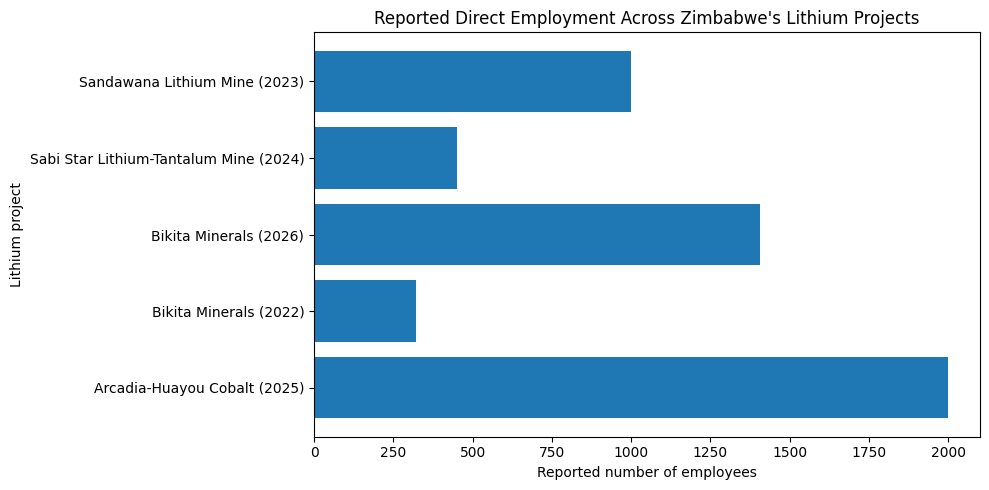

In [ ]:

import matplotlib.pyplot as plt

# Select employment observations
employment = core_data[
    core_data["Indicator"].str.contains(
        "Employment", case=False, na=False
    )
].copy()

# Attach project names
project_names = projects.set_index(
    "Project_ID"
)["Project_Name"]

employment["Project"] = employment["Project_ID"].map(
    project_names
)

# Create labels including observation year
employment["Label"] = (
    employment["Project"] + " (" +
    employment["Year"].astype(str) + ")"
)

# Display the data before plotting
display(
    employment[
        ["Project", "Year", "Indicator", "Value", "Unit"]
    ]
)

# Create chart
plt.figure(figsize=(10, 5))

plt.barh(
    employment["Label"],
    employment["Value"]
)

plt.xlabel("Reported number of employees")
plt.ylabel("Lithium project")
plt.title("Reported Direct Employment Across Zimbabwe's Lithium Projects")

plt.tight_layout()
plt.show()


### Research Question 1 & 2 Data Extraction: Investment, Employment, Production & Beneficiation
We will restructure the observations into a readable comparative table focusing on key indicators.

In [ ]:
import pandas as pd

# Let's pivot and display key metrics for each core project to address RQ1 & RQ2
pivot_df = core_data.pivot_table(
    index=['Project_ID', 'Indicator'],
    values=['Year', 'Value', 'Unit'],
    aggfunc='first'
).reset_index()

pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.1f' % x if x > 1e3 else '%.3f' % x)

print("--- DETAILED INDICATORS PER CORE PROJECT ---")
display(pivot_df.sort_values(by=['Project_ID', 'Indicator']))

### Research Question 3 Data Extraction: Ownership & Control
We will pull the project name, location, and registry details related to ownership.

In [ ]:
# Show project registry columns to identify ownership information
print("--- PROJECT REGISTRY DETAIL ---")
registry_cols = [col for col in projects.columns if any(x in col.lower() for x in ['owner', 'parent', 'id', 'name', 'country', 'share', 'equity'])]
display(core_projects[registry_cols if len(registry_cols) > 0 else core_projects.columns].head())

--- PROJECT REGISTRY DETAIL ---


,Project_ID,Project_Name,First_Evidence_Year,Source_IDs
0,Zim_L1,Arcadia-Huayou Cobalt,2016,SRC_01; SRC_08; SRC_09; SRC_17; SRC_25; SRC_32
1,Zim_L2,Bikita Minerals,1950,SRC_01; SRC_02; SRC_10; SRC_16; SRC_18; SRC_24...
2,Zim_L3,Sabi Star Lithium-Tantalum Mine,2018,SRC_01; SRC_02; SRC_11; SRC_16; SRC_19; SRC_27
3,Zim_L4,Sandawana Lithium Mine,2022,SRC_01; SRC_02; SRC_12; SRC_20; SRC_24


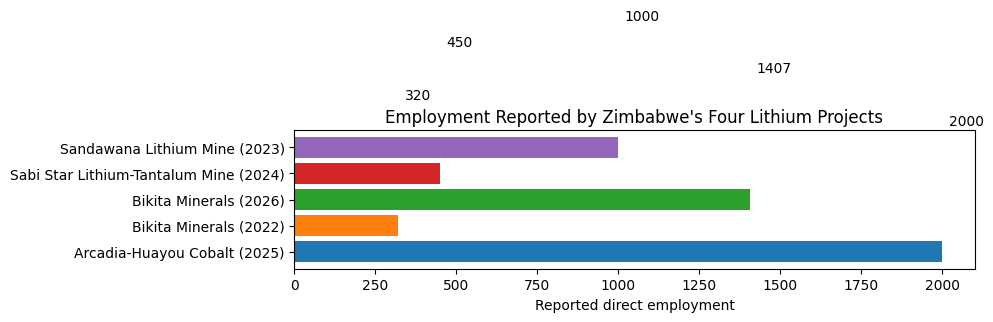

In [ ]:

plt.figure(figsize=(10, 6))

for _, row in employment.iterrows():
    plt.barh(
        f"{row['Project']} ({int(row['Year'])})",
        row["Value"]
    )

    plt.text(
        row["Value"] + 20,
        f"{row['Value']:.0f}",
        f"{row['Value']:.0f}",
        va="center"
    )

plt.xlabel("Reported direct employment")
plt.title("Employment Reported by Zimbabwe's Four Lithium Projects")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# Filter for investment-related indicators
investment_indicators = [
    'Acquisition_Price_Paid',
    'Capex_Spent_Reported',
    'Capex_Spent_Sulphate_Plant',
    'Capex_Spent_Expansion',
    'Capex_Committed',
    'Capex_Planned_Announced'
]

investment_data = core_data[core_data['Indicator'].isin(investment_indicators)].copy()

# Map project names
project_names = core_projects.set_index('Project_ID')['Project_Name']
investment_data['Project_Name'] = investment_data['Project_ID'].map(project_names)

# Define categorisation mapping
def categorize_investment(indicator):
    if 'Acquisition' in indicator:
        return 'Acquisition Price Paid'
    elif 'Spent' in indicator:
        return 'Capex Spent (Actual)'
    elif 'Committed' in indicator:
        return 'Capex Committed'
    elif 'Planned' in indicator or 'Announced' in indicator:
        return 'Capex Planned / Announced'
    return 'Other'

investment_data['Category'] = investment_data['Indicator'].apply(categorize_investment)

# Create a structured comparative view
investment_pivot = investment_data.pivot_table(
    index=['Project_Name', 'Project_ID'],
    columns='Category',
    values='Value',
    aggfunc='sum'
).fillna(0)

# Format for monetary readability (Millions USD)
investment_pivot_m = investment_pivot / 1_000_000

print("--- INVESTMENT METRICS BY CATEGORY (in USD Millions) ---")
display(investment_pivot_m.style.format("${:,.1f}M"))

--- INVESTMENT METRICS BY CATEGORY (in USD Millions) ---


,Category,Acquisition Price Paid,Capex Committed,Capex Planned / Announced,Capex Spent (Actual)
Project_Name,Project_ID,,,,
Arcadia-Huayou Cobalt,Zim_L1,$422.0M,$0.0M,$0.0M,$700.0M
Bikita Minerals,Zim_L2,$180.0M,$400.0M,$0.0M,$300.0M
Sabi Star Lithium-Tantalum Mine,Zim_L3,$76.5M,$0.0M,$244.0M,$0.0M
Sandawana Lithium Mine,Zim_L4,$0.0M,$250.0M,$0.0M,$0.0M


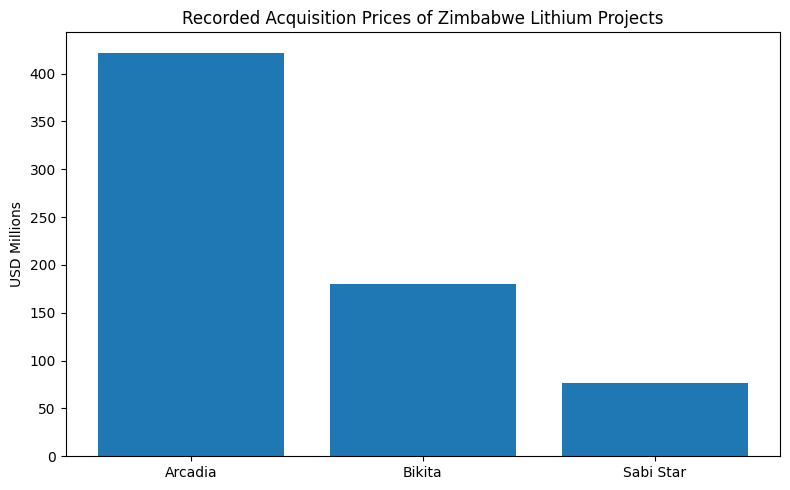

In [ ]:

import matplotlib.pyplot as plt

acquisition = {
    "Arcadia": 422,
    "Bikita": 180,
    "Sabi Star": 76.5
}

plt.figure(figsize=(8, 5))
plt.bar(acquisition.keys(), acquisition.values())

plt.ylabel("USD Millions")
plt.title("Recorded Acquisition Prices of Zimbabwe Lithium Projects")

plt.tight_layout()
plt.show()


Capital expenditure comparison

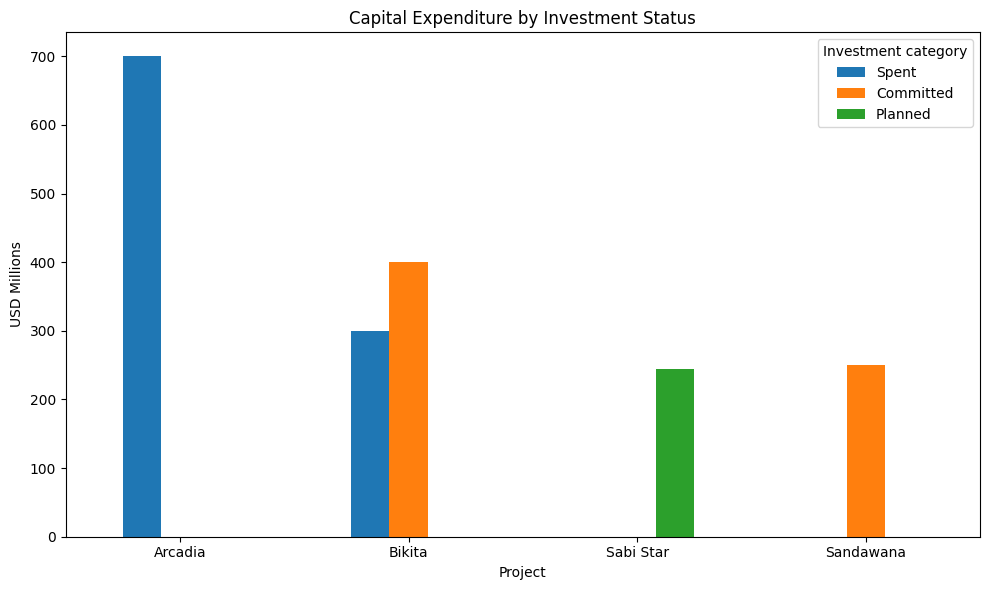

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

capex_data = {
    "Project": ["Arcadia", "Bikita", "Sabi Star", "Sandawana"],
    "Spent": [700, 300, None, None],
    "Committed": [None, 400, None, 250],
    "Planned": [None, None, 244, None]
}

capex_df = pd.DataFrame(capex_data)

capex_df.set_index("Project").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("USD Millions")
plt.title("Capital Expenditure by Investment Status")
plt.xticks(rotation=0)
plt.legend(title="Investment category")
plt.tight_layout()
plt.show()


STEP 5

In [ ]:

findings = pd.DataFrame({
    "Finding": [
        "Foreign ownership and acquisition",
        "Investment status",
        "Employment generation",
        "Beneficiation and processing"
    ],
    "Research_Question": [
        "Who owns and controls the lithium projects?",
        "How much investment is spent, committed or planned?",
        "What employment opportunities are generated?",
        "How much processing and value addition takes place locally?"
    ],
    "Interpretation": [
        "Examine foreign ownership and control over lithium assets.",
        "Distinguish actual capital expenditure from commitments and announcements.",
        "Investigate the quality and distribution of employment benefits.",
        "Examine Zimbabwe's position in the lithium global value chain."
    ],
    "Evidence_Status": [
        "Preliminary",
        "Preliminary",
        "Preliminary",
        "Preliminary"
    ]
})

findings.to_excel(
    "Zimbabwe_Lithium_Preliminary_Findings.xlsx",
    index=False
)

print("Research findings report created successfully!")
display(findings)


Research findings report created successfully!


,Finding,Research_Question,Interpretation,Evidence_Status
0,Foreign ownership and acquisition,Who owns and controls the lithium projects?,Examine foreign ownership and control over lit...,Preliminary
1,Investment status,"How much investment is spent, committed or pla...",Distinguish actual capital expenditure from co...,Preliminary
2,Employment generation,What employment opportunities are generated?,Investigate the quality and distribution of em...,Preliminary
3,Beneficiation and processing,How much processing and value addition takes p...,Examine Zimbabwe's position in the lithium glo...,Preliminary


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=findings)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
findings.to_csv(
    "Zimbabwe_Lithium_Preliminary_Findings.csv",
    index=False
)